# Classification is a problem of predicting whether predicting something is one thing or another (there can be multiple things as the options)


# 1. Make classification and get it ready

In [1]:
import sklearn
from sklearn.datasets import make_circles

In [2]:
#Make 1000 samples
n_samples = 1000

#Create circles
X, y = make_circles(n_samples, noise=0.03, random_state=42)

In [3]:
len(X), len(y)

(1000, 1000)

In [4]:
print(f"First 5 samples of X:\n {X[:5]}")
print(f"First 5 samples of y:\n {y[:5]}")

First 5 samples of X:
 [[ 0.75424625  0.23148074]
 [-0.75615888  0.15325888]
 [-0.81539193  0.17328203]
 [-0.39373073  0.69288277]
 [ 0.44220765 -0.89672343]]
First 5 samples of y:
 [1 1 1 1 0]


In [5]:
# Make DataFrame of circle data
import pandas as pd
circles = pd.DataFrame({"X1":X[:, 0],
                        "X2":X[:, 1],
                        "label":y})
circles.head(10)

,X1,X2,label
0,0.754246,0.231481,1
1,-0.756159,0.153259,1
2,-0.815392,0.173282,1
3,-0.393731,0.692883,1
4,0.442208,-0.896723,0
5,-0.479646,0.676435,1
6,-0.013648,0.803349,1
7,0.771513,0.147760,1
8,-0.169322,-0.793456,1
9,-0.121486,1.021509,0


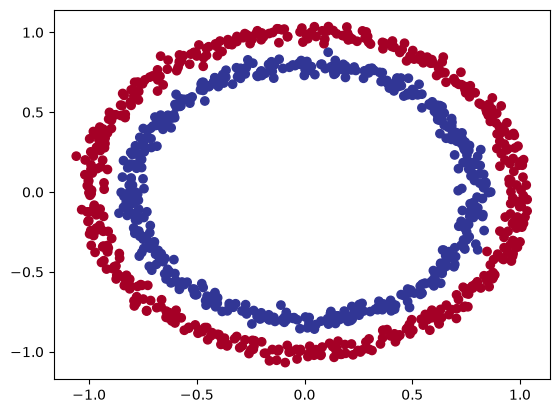

In [6]:
# Let use see what is our data and what are we working on 
import matplotlib.pyplot as plt
plt.scatter(x=X[:, 0],
            y=X[:, 1],
            c=y,
            cmap=plt.cm.RdYlBu);

#here we are predicting the blue and red dot and this is a toy dataset for experimenting and practicing code

### 1.1 Check input and output shapes

In [7]:
X.shape, y.shape

((1000, 2), (1000,))

In [8]:
X

array([[ 0.75424625,  0.23148074],
       [-0.75615888,  0.15325888],
       [-0.81539193,  0.17328203],
       ...,
       [-0.13690036, -0.81001183],
       [ 0.67036156, -0.76750154],
       [ 0.28105665,  0.96382443]], shape=(1000, 2))

In [9]:
# View the first example of features and labels
X_sample = X[0]
y_sample = y[0]

print(X_sample)
print(y_sample)
print(X_sample.shape, y_sample.shape)

[0.75424625 0.23148074]
1
(2,) ()


### 1.2 Turn data into tensors and create train and test splits

In [10]:
import torch
torch.__version__

'2.14.0+cu130'

In [11]:
#turn data into tensors
X = torch.from_numpy(X).type(torch.float32)
y = torch.from_numpy(y).type(torch.float32)

In [12]:
type(X), type(y)

(torch.Tensor, torch.Tensor)

In [13]:
# Split the data into training and test split 
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [14]:
len(X_train), len(X_test), len(y_train), len(y_test)

(800, 200, 800, 200)

In [15]:
n_samples

1000

# 2. Building a model

#### let us build a model to classify our blue and red dots
#### To do so:
##### 1. Setup device agonistic so our code will run on the accelerator (GPU) if there is one
##### 2. Construct a model(by subclassing `nn.Module`)
##### 3. Define a loss function and optimizer 
##### 4. Create a training loop and test loop 

In [16]:
import torch
from torch import nn

# Make device agnostic code 
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [17]:
X_train

tensor([[ 0.6579, -0.4651],
        [ 0.6319, -0.7347],
        [-1.0086, -0.1240],
        ...,
        [ 0.0157, -1.0300],
        [ 1.0110,  0.1680],
        [ 0.5578, -0.5709]])

#### Now we have setup the device agnostic code above now let's create a model that :

##### 1. Subclassess `nn.Module` (almost all models in Pytorch sublcass `nn.Module`)
##### 2. Create 2 linear `nn.Linear()` - layers that are capable of handling the shapes of our data 
##### 3. Defines a `forward()` method that outlines the forward pass (or forward propagation) of the model 
##### 4. Instatiate an instance of our model clasa and send it to the target device

In [18]:
#1. Construct a model that subclasses nn.Module
class CircleModelV0(nn.Module):
    def __init__(self):
        super().__init__()
        # 2. Create two nn.Linear layer copable of handling the data
        self.layer_1 = nn.Linear(in_features=2, out_features=5)
        self.layer_2 = nn.Linear(in_features=5, out_features=1)   # this second layer input feature must match the output feature of first layer

        #3. forward loop
    def forward(self, x):
        return self.layer_2(self.layer_1(X)) # x goes into layer 1 and the output of layer 1 goes into layer 2 and then layer 2 goes to the output

# 4. Instantiate an instance of our model class
model_0 = CircleModelV0().to(device)
model_0

CircleModelV0(
  (layer_1): Linear(in_features=2, out_features=5, bias=True)
  (layer_2): Linear(in_features=5, out_features=1, bias=True)
)

### Let us replicate the model above using `nn.Sequential()`

In [19]:
model_0 = nn.Sequential(nn.Linear(in_features=2, out_features=5),
                       nn.Linear(in_features=5, out_features=1)
                       ).to(device)
model_0

Sequential(
  (0): Linear(in_features=2, out_features=5, bias=True)
  (1): Linear(in_features=5, out_features=1, bias=True)
)

In [20]:
model_0.state_dict()

OrderedDict([('0.weight',
              tensor([[-0.0561, -0.1974],
                      [ 0.5107, -0.0459],
                      [ 0.2703,  0.1442],
                      [-0.1720,  0.4589],
                      [-0.1726,  0.5994]], device='cuda:0')),
             ('0.bias',
              tensor([-0.4060, -0.3818, -0.6365,  0.6369, -0.0058], device='cuda:0')),
             ('1.weight',
              tensor([[-0.4337, -0.1410, -0.1197, -0.1825, -0.3322]], device='cuda:0')),
             ('1.bias', tensor([-0.4331], device='cuda:0'))])

In [21]:
# Make some predicitons with the model 
with torch.inference_mode():
    untrained_preds = model_0(X_test.to(device))
print(f"Len of predictions: {len(untrained_preds)}, Shape:{untrained_preds.shape}")
print(f"Len of test samples: {len(X_test)}, Shape: {X_test.shape}")
print(f"\nFirst 10 predictions:\n {untrained_preds[:10]}")
print(f"\nFirst 10 labels:\n{y_test[:10]}")

Len of predictions: 200, Shape:torch.Size([200, 1])
Len of test samples: 200, Shape: torch.Size([200, 2])

First 10 predictions:
 tensor([[-0.3867],
        [-0.4410],
        [-0.1820],
        [-0.4450],
        [-0.0831],
        [-0.1171],
        [-0.3484],
        [-0.2723],
        [-0.1865],
        [-0.4436]], device='cuda:0')

First 10 labels:
tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.])


In [22]:
X_test[:10], y_test[:10]

(tensor([[-0.3752,  0.6827],
         [ 0.0154,  0.9600],
         [-0.7028, -0.3147],
         [-0.2853,  0.9664],
         [ 0.4024, -0.7438],
         [ 0.6323, -0.5711],
         [ 0.8561,  0.5499],
         [ 1.0034,  0.1903],
         [-0.7489, -0.2951],
         [ 0.0538,  0.9739]]),
 tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.]))

### 2.1 Setup a loss function and optimizer 

In [23]:
# Loss functions are how wrong your models predictions are.
loss_fn = nn.BCEWithLogitsLoss()    # this comes with sigmoid activation 
optimizer = torch.optim.SGD(params=model_0.parameters(),
                           lr=0.1)

In [24]:
# Calculate accuracy - out of 100 examples what % does our model get right 
def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct/len(y_pred)) * 100
    return acc

# 3. Training the model

#### To train our model we need training loop :
##### 1. Forward pass
##### 2. Calculate the loss
##### 3. Optimizer zero grad
##### 4. Loss backward(backprop)
##### 5. Optimizer step(gradient descent)

### 3.1 Going from raw logits - A logit is the raw, unnormalized score a neural network outputs before any probability-converting function is applied. 
#### So we can convert this `logits` into prediction probabilities by passing them to some kind of activation function (eg sigmoid for binary classification and softmax for multi class)

In [25]:
# View the first 5 outputs of the forward pass on the test data
model_0.eval()
with torch.inference_mode():
    y_logits = model_0(X_test.to(device))[:5]
y_logits

tensor([[-0.3867],
        [-0.4410],
        [-0.1820],
        [-0.4450],
        [-0.0831]], device='cuda:0')

In [26]:
# Use the sigmoid activation function on our model logits to turn them into probabilities
y_pred_probs = torch.sigmoid(y_logits)
y_pred_probs 

tensor([[0.4045],
        [0.3915],
        [0.4546],
        [0.3906],
        [0.4792]], device='cuda:0')

### For our prediction probability values we need to perform a range style rounding for this dataset like:
#### Eg: y_pred_probs >= 0.5 then it is class 1 (like a red dot for eg)
#### y_pred_probs <= 0.5 then it is class 1 (like a blue dot for eg)

In [27]:
y_preds = torch.round(y_pred_probs)

In [28]:
y_pred_labels = torch.round(torch.sigmoid(model_0(X_test.to(device))[:5]))
print(torch.eq(y_preds.squeeze(), y_pred_labels.squeeze()))
y_preds.squeeze()

tensor([True, True, True, True, True], device='cuda:0')


tensor([0., 0., 0., 0., 0.], device='cuda:0')

### 3.2 Building a training and testing loop

In [29]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Set the number of epochs 
epochs = 1500

# Put data to target device 
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

# Build training and evaluation loop 
for epoch in range(epochs):
    # training
    model_0.train()

    # 1. Forward pass
    y_logits = model_0(X_train).squeeze()
    y_pred = torch.round(torch.sigmoid(y_logits))

    #2. Calculate loss
    loss = loss_fn(y_logits, y_train)
    acc = accuracy_fn(y_true=y_train,
                     y_pred=y_pred)

    # 3. Optimizer zero grad
    optimizer.zero_grad()

    # 4. backprop
    loss.backward()

    #5. Optimizer step
    optimizer.step()

    ### Testing 
    model_0.eval()
    with torch.inference_mode():
        1. # forward pass
        test_logits = model_0(X_test).squeeze()
        test_pred = torch.round(torch.sigmoid(test_logits))

        # 2. Calculate test loss
        test_loss = loss_fn(test_logits, y_test)
        test_acc = accuracy_fn(y_true=y_test, y_pred=test_pred)

    if epoch % 10 == 0:
        print(epoch)
        print(loss)

0
tensor(0.7035, device='cuda:0',
       grad_fn=<BinaryCrossEntropyWithLogitsBackward0>)
10
tensor(0.6974, device='cuda:0',
       grad_fn=<BinaryCrossEntropyWithLogitsBackward0>)
20
tensor(0.6955, device='cuda:0',
       grad_fn=<BinaryCrossEntropyWithLogitsBackward0>)
30
tensor(0.6948, device='cuda:0',
       grad_fn=<BinaryCrossEntropyWithLogitsBackward0>)
40
tensor(0.6944, device='cuda:0',
       grad_fn=<BinaryCrossEntropyWithLogitsBackward0>)
50
tensor(0.6942, device='cuda:0',
       grad_fn=<BinaryCrossEntropyWithLogitsBackward0>)
60
tensor(0.6940, device='cuda:0',
       grad_fn=<BinaryCrossEntropyWithLogitsBackward0>)
70
tensor(0.6938, device='cuda:0',
       grad_fn=<BinaryCrossEntropyWithLogitsBackward0>)
80
tensor(0.6937, device='cuda:0',
       grad_fn=<BinaryCrossEntropyWithLogitsBackward0>)
90
tensor(0.6936, device='cuda:0',
       grad_fn=<BinaryCrossEntropyWithLogitsBackward0>)
100
tensor(0.6935, device='cuda:0',
       grad_fn=<BinaryCrossEntropyWithLogitsBackward0>)

# 4.Make predictions

In [30]:
# Use the helper function from PyTorch Zero to Hero Academy 
import requests
from pathlib import Path

if Path("helper_functions.py").is_file():
    print("helper_functions.py already exists, skipping download")
else:
    print("Downloading helper_functions.py")
    request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/refs/heads/main/helper_functions.py")
    with open("helper_functions.py", "wb") as f:
        f.write(request.content)

from helper_functions import plot_predictions, plot_decision_boundary
    

helper_functions.py already exists, skipping download


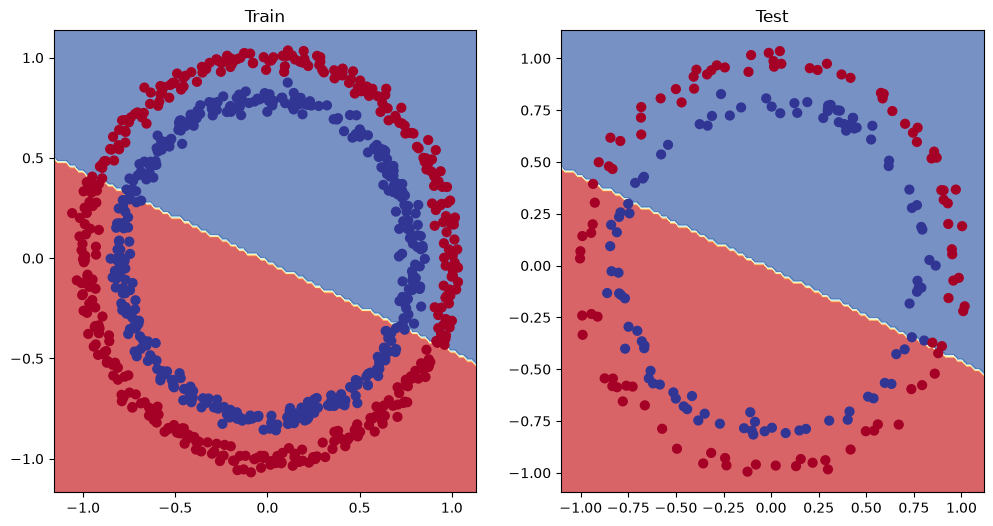

In [31]:
# Plot decision boundary of the model 
plt.figure(figsize=(12, 6))
plt.subplot(1,2,1)
plt.title("Train")
plot_decision_boundary(model_0, X_train, y_train)
plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(model_0, X_test, y_test)
           

# 5. Improving a model
#### 1. Add more layers
#### 2. Add more hidden units (hidden layer - neurons)
#### 3. Fit for longer 
#### 4. Change in the activation function 
#### 5. Change learning rate 
#### 6. Change the loss function 

In [32]:
model_0.state_dict()

OrderedDict([('0.weight',
              tensor([[-0.1197, -0.3279],
                      [ 0.4919, -0.0870],
                      [ 0.2538,  0.1076],
                      [-0.1799,  0.4370],
                      [-0.2030,  0.5297]])),
             ('0.bias', tensor([-0.4443, -0.3949, -0.6483,  0.6246, -0.0326])),
             ('1.weight',
              tensor([[-0.5481, -0.1292, -0.1087, -0.0350, -0.2103]])),
             ('1.bias', tensor([-0.3491]))])

In [33]:
class CircleModelV1(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=2, out_features=10)
        self.layer_2 = nn.Linear(in_features=10, out_features=10)
        self.layer_3 = nn.Linear(in_features=10, out_features=1)

    def forward(self, x):
        return self.layer_3(self.layer_2(self.layer_1(x)))   # this way of writing opeartions speeds up 

model_1 = CircleModelV1().to(device)
model_1

CircleModelV1(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
)

In [34]:
model_1.state_dict()

OrderedDict([('layer_1.weight',
              tensor([[ 0.5406,  0.5869],
                      [-0.1657,  0.6496],
                      [-0.1549,  0.1427],
                      [-0.3443,  0.4153],
                      [ 0.6233, -0.5188],
                      [ 0.6146,  0.1323],
                      [ 0.5224,  0.0958],
                      [ 0.3410, -0.0998],
                      [ 0.5451,  0.1045],
                      [-0.3301,  0.1802]], device='cuda:0')),
             ('layer_1.bias',
              tensor([-0.3258, -0.0829, -0.2872,  0.4691, -0.5582, -0.3260, -0.1997, -0.4252,
                       0.0667, -0.6984], device='cuda:0')),
             ('layer_2.weight',
              tensor([[ 0.2856, -0.2686,  0.2441,  0.0526, -0.1027,  0.1954,  0.0493,  0.2555,
                        0.0346, -0.0997],
                      [ 0.0850, -0.0858,  0.1331,  0.2823,  0.1828, -0.1382,  0.1825,  0.0566,
                        0.1606, -0.1927],
                      [-0.3130, -0.122

In [35]:
# Create a loss function 
loss_fn = nn.BCEWithLogitsLoss()

# Create an optimizer
optimizer = torch.optim.SGD(params=model_1.parameters(), lr=0.1)

In [36]:
#Write a training loop and evaluation model
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# train for longer
epochs = 1000

# Put data on target device 
X_train, y_train = X_train.to(device), y_train.to(device)
X_test , y_test = X_test.to(device), y_test.to(device)

for epoch in range(epochs):
    model_1.train()

    y_logits = model_1(X_train).squeeze()
    y_pred = torch.round(torch.sigmoid(y_logits))

    # Calculate the loss
    loss = loss_fn(y_logits, y_train)
    acc = accuracy_fn(y_true=y_train, y_pred=y_pred)

    # Optimizer zero grad
    optimizer.zero_grad()

    #backward
    loss.backward()

    # Optimzier step
    optimizer.step()

    #testing
    model_1.eval()
    with torch.inference_mode():
        test_logits = model_1(X_test).squeeze()
        test_pred = torch.round(torch.sigmoid(test_logits))

        # calculate loss
        test_loss = loss_fn(test_logits, y_test)
        test_acc = accuracy_fn(y_true=y_test, y_pred=test_pred)

    #Print
    if epoch % 100 ==0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Acc:{acc:.2f}% | Test Loss: {test_loss:.5,f} Test acc: {test_acc:.2f}%")
        

Epoch: 0 | Loss: 0.69396, Acc:50.88% | Test Loss: 0.692,61 Test acc: 51.00%
Epoch: 100 | Loss: 0.69305, Acc:50.38% | Test Loss: 0.693,79 Test acc: 48.00%
Epoch: 200 | Loss: 0.69299, Acc:51.12% | Test Loss: 0.694,37 Test acc: 46.00%
Epoch: 300 | Loss: 0.69298, Acc:51.62% | Test Loss: 0.694,58 Test acc: 45.00%
Epoch: 400 | Loss: 0.69298, Acc:51.12% | Test Loss: 0.694,65 Test acc: 46.00%
Epoch: 500 | Loss: 0.69298, Acc:51.00% | Test Loss: 0.694,67 Test acc: 46.00%
Epoch: 600 | Loss: 0.69298, Acc:51.00% | Test Loss: 0.694,68 Test acc: 46.00%
Epoch: 700 | Loss: 0.69298, Acc:51.00% | Test Loss: 0.694,68 Test acc: 46.00%
Epoch: 800 | Loss: 0.69298, Acc:51.00% | Test Loss: 0.694,68 Test acc: 46.00%
Epoch: 900 | Loss: 0.69298, Acc:51.00% | Test Loss: 0.694,68 Test acc: 46.00%


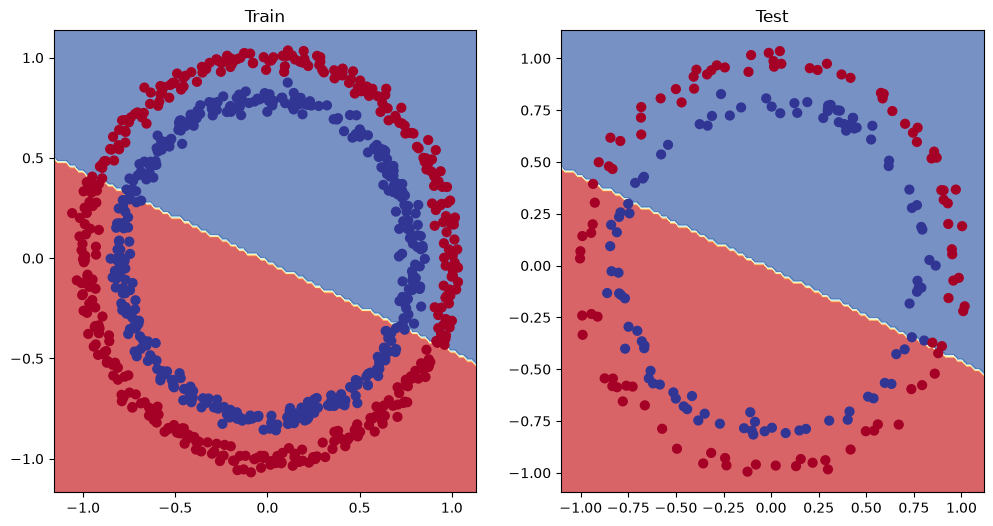

In [37]:
# Plot decision boundary of the model 
plt.figure(figsize=(12, 6))
plt.subplot(1,2,1)
plt.title("Train")
plot_decision_boundary(model_1, X_train, y_train)
plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(model_1, X_test, y_test)

### 5.1 Preparing the data to see if our model can fit a straight line 

#### One way to troubleshoot to a larger problem is to test out a smaller problem

In [38]:
# Create some data
weight = 0.7
bias = 0.3
start = 0
end = 1
step = 0.01

# create data
X_regression = torch.arange(start, end, step).unsqueeze(dim=1)
y_regression = weight * X_regression + bias 

# check the data 
print(len(X_regression))
X_regression[:5], y_regression[:5]

100


(tensor([[0.0000],
         [0.0100],
         [0.0200],
         [0.0300],
         [0.0400]]),
 tensor([[0.3000],
         [0.3070],
         [0.3140],
         [0.3210],
         [0.3280]]))

In [93]:
#Create train, test split 
train_split = int(0.8 * len(X_regression))
X_train_regression, y_train_regression = X_regression[:train_split], y_regression[:train_split]
X_test_regression , y_test_regression = X_regression[train_split:], y_regression[train_split:]

len(X_train_regression), len(X_test_regression), len(y_train_regression), len(y_test_regression)

(80, 20, 80, 20)

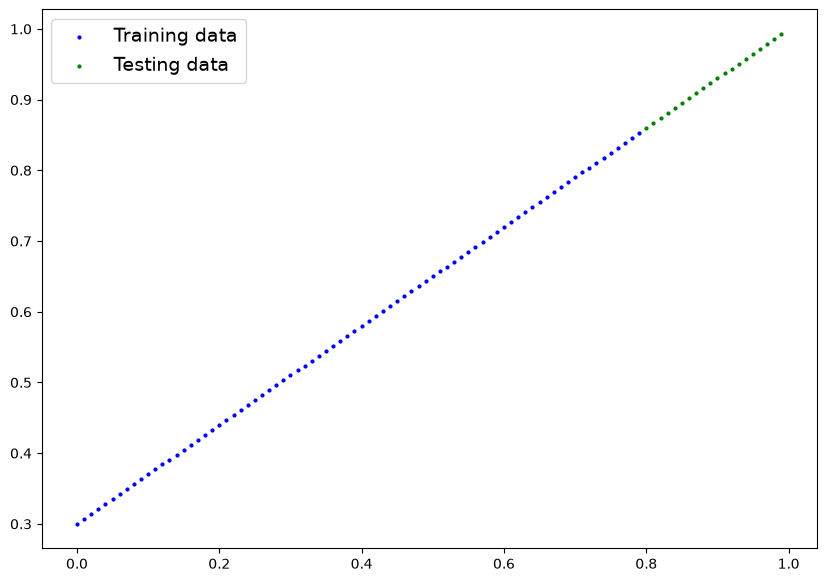

In [94]:
plot_predictions(train_data=X_train_regression,
                train_labels=y_train_regression,
                test_data=X_test_regression,
                test_labels=y_test_regression)

### 5.2 Adjusting model_1 to fit  a straight line 

In [41]:
# same architecture as model_1
model_2 = nn.Sequential(
    nn.Linear(in_features=1, out_features=10),
    nn.Linear(in_features=10, out_features=10),
    nn.Linear(in_features=10, out_features=1)
).to(device)

In [42]:
model_2

Sequential(
  (0): Linear(in_features=1, out_features=10, bias=True)
  (1): Linear(in_features=10, out_features=10, bias=True)
  (2): Linear(in_features=10, out_features=1, bias=True)
)

In [43]:
# loss and optimizer
loss_fn = nn.L1Loss()
optimizer = torch.optim.SGD(params = model_2.parameters(), lr=0.01)

In [44]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

epochs = 900

X_train_regression , y_train_regression = X_train_regression.to(device), y_train_regression.to(device)
X_test_regression, y_test_regression = X_test_regression.to(device), y_test_regression.to(device)

#training
for epoch in range(epochs):
    y_pred = model_2(X_train_regression)
    loss = loss_fn(y_pred, y_train_regression)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # testing
    model_2.eval()
    with torch.inference_mode():
        test_pred = model_2(X_test_regression)
        test_loss = loss_fn(test_pred, y_test_regression)

    if epoch % 10 == 0:
           print(f"Epoch: {epoch} | Loss: {loss:.5f} | Test Loss: {test_loss:.5,f}")

Epoch: 0 | Loss: 0.75986 | Test Loss: 0.911,03
Epoch: 10 | Loss: 0.40240 | Test Loss: 0.504,74
Epoch: 20 | Loss: 0.06007 | Test Loss: 0.101,51
Epoch: 30 | Loss: 0.01559 | Test Loss: 0.032,31
Epoch: 40 | Loss: 0.03092 | Test Loss: 0.001,11
Epoch: 50 | Loss: 0.03196 | Test Loss: 0.001,08
Epoch: 60 | Loss: 0.03192 | Test Loss: 0.001,70
Epoch: 70 | Loss: 0.03081 | Test Loss: 0.000,97
Epoch: 80 | Loss: 0.03077 | Test Loss: 0.001,50
Epoch: 90 | Loss: 0.02967 | Test Loss: 0.000,92
Epoch: 100 | Loss: 0.02858 | Test Loss: 0.000,81
Epoch: 110 | Loss: 0.02962 | Test Loss: 0.001,97
Epoch: 120 | Loss: 0.02748 | Test Loss: 0.000,91
Epoch: 130 | Loss: 0.02852 | Test Loss: 0.001,81
Epoch: 140 | Loss: 0.02850 | Test Loss: 0.002,46
Epoch: 150 | Loss: 0.02744 | Test Loss: 0.001,69
Epoch: 160 | Loss: 0.02638 | Test Loss: 0.001,23
Epoch: 170 | Loss: 0.02637 | Test Loss: 0.001,62
Epoch: 180 | Loss: 0.02532 | Test Loss: 0.001,25
Epoch: 190 | Loss: 0.02636 | Test Loss: 0.002,84
Epoch: 200 | Loss: 0.02533 | Te

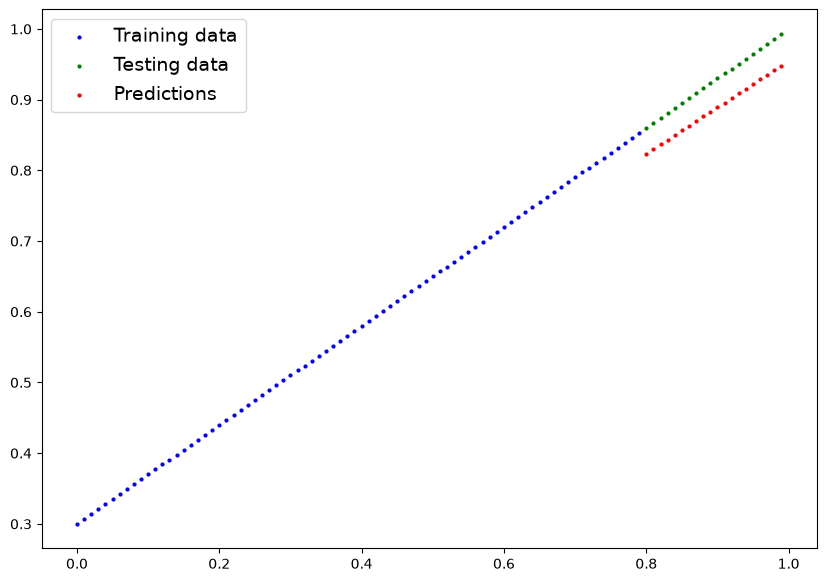

In [90]:
# turn on evaluation mode
model_2.eval()
with torch.inference_mode():
    y_preds = model_2(X_test_regression)

plot_predictions(train_data=X_train_regression.cpu(), 
                 train_labels=y_train_regression.cpu(), 
                 test_data=X_test_regression.cpu(), 
                 test_labels=y_test_regression.cpu(), 
                 predictions=y_preds.cpu())

# 6. The missing piece: non-linearity

#### What patterns could you draw if you were given an infinite amount of straight and non straight lines?


### 6.1 Recreating non-linear data (red and blue circles)

In [46]:
import sklearn
from sklearn.datasets import make_circles

#Make 1000 samples
n_samples = 1000

#Create circles
X, y = make_circles(n_samples, noise=0.03, random_state=42)

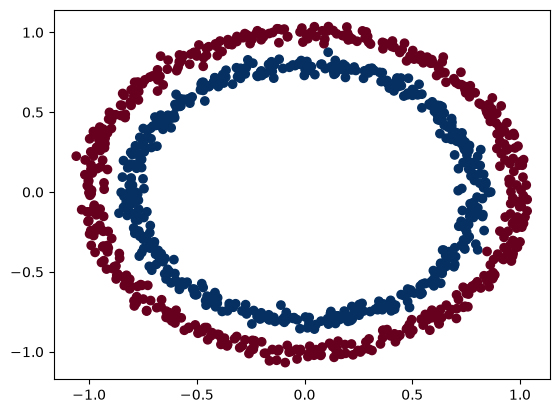

In [47]:
plt.scatter(x=X[:, 0],
            y=X[:, 1],
            c=y,
            cmap=plt.cm.RdBu);

In [48]:
# Convert data to tensors and create train and test
import torch
from sklearn.model_selection import train_test_split

X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

# Split train and test
X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=0.2, random_state=42)

In [49]:
X_train[:3], y_train[:3]

(tensor([[ 0.6579, -0.4651],
         [ 0.6319, -0.7347],
         [-1.0086, -0.1240]]),
 tensor([1., 0., 0.]))

### 6.2 Building a model with non-linearity

In [88]:
# Build a model with non-linear activation functions
from torch import nn
class CircleModelV2(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=2, out_features=10)
        self.layer_2 = nn.Linear(in_features=10, out_features=10)
        self.layer_3 = nn.Linear(in_features=10, out_features=1)
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))

model_3 = CircleModelV2().to(device)
model_3

CircleModelV2(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
  (relu): ReLU()
)

In [80]:
# Setup loss funciton
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model_3.parameters(), lr=0.1)

### 6.3 Training the model with non-linear activation functions

In [52]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Put all data on target device
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

epochs = 1000

for epoch in range(epochs):
    model_3.train()

    y_logits = model_3(X_train).squeeze()
    y_pred = torch.round(torch.sigmoid(y_logits))

    # Calculate the loss
    loss = loss_fn(y_logits, y_train)
    acc = accuracy_fn(y_true=y_train,
                     y_pred=y_pred)

    # Optimzier
    optimizer.zero_grad()

    #backprop
    loss.backward()

    # optimizer step
    optimizer.step()

    ### Testing
    model_3.eval()
    with torch.inference_mode():
        test_logits = model_3(X_test).squeeze()
        test_perd = torch.round(torch.sigmoid(test_logits))

        test_loss = loss_fn(test_logits, y_test)
        test_acc = accuracy_fn(y_true=y_test,
                              y_pred=test_pred)

    if epoch % 100 == 0:
            print(f"Epoch: {epoch} | Loss: {loss:.4f}, Acc:{acc:.2f}% | Test Loss: {test_loss:.4f} Test acc: {test_acc:.2f}%")

Epoch: 0 | Loss: 0.6929, Acc:50.00% | Test Loss: 0.6932 Test acc: 0.00%
Epoch: 100 | Loss: 0.6912, Acc:52.88% | Test Loss: 0.6910 Test acc: 0.00%
Epoch: 200 | Loss: 0.6898, Acc:53.37% | Test Loss: 0.6894 Test acc: 0.00%
Epoch: 300 | Loss: 0.6879, Acc:53.00% | Test Loss: 0.6872 Test acc: 0.00%
Epoch: 400 | Loss: 0.6852, Acc:52.75% | Test Loss: 0.6841 Test acc: 0.00%
Epoch: 500 | Loss: 0.6810, Acc:52.75% | Test Loss: 0.6794 Test acc: 0.00%
Epoch: 600 | Loss: 0.6751, Acc:54.50% | Test Loss: 0.6729 Test acc: 0.00%
Epoch: 700 | Loss: 0.6666, Acc:58.38% | Test Loss: 0.6632 Test acc: 0.00%
Epoch: 800 | Loss: 0.6516, Acc:64.00% | Test Loss: 0.6476 Test acc: 0.00%
Epoch: 900 | Loss: 0.6236, Acc:74.00% | Test Loss: 0.6215 Test acc: 0.00%


In [53]:
model_3.state_dict()

OrderedDict([('layer_1.weight',
              tensor([[ 0.6760,  0.8035],
                      [-0.1997,  0.7568],
                      [-0.1549,  0.1427],
                      [-0.9637,  0.2292],
                      [ 0.5717, -1.3426],
                      [ 0.6689,  0.1840],
                      [ 0.7970,  0.2595],
                      [ 0.3410, -0.0998],
                      [ 0.6555,  0.3186],
                      [-0.3301,  0.1802]], device='cuda:0')),
             ('layer_1.bias',
              tensor([-0.3761, -0.2008, -0.2872,  0.2803, -0.4513, -0.3364, -0.3300, -0.4252,
                      -0.1989, -0.6984], device='cuda:0')),
             ('layer_2.weight',
              tensor([[ 1.3081e-01, -3.7347e-01,  2.4414e-01, -4.3348e-02, -2.7270e-01,
                        1.0512e-01, -4.7109e-02,  2.5550e-01, -4.9248e-02, -9.9730e-02],
                      [ 7.9469e-01,  3.8277e-01,  1.3309e-01,  7.5399e-01,  9.7241e-01,
                        2.6996e-01,  6.2185e-01

### 6.4 Evaluating model

In [54]:
model_3.eval()
with torch.inference_mode():
    y_preds = torch.round(torch.sigmoid(model_3(X_test))).squeeze()

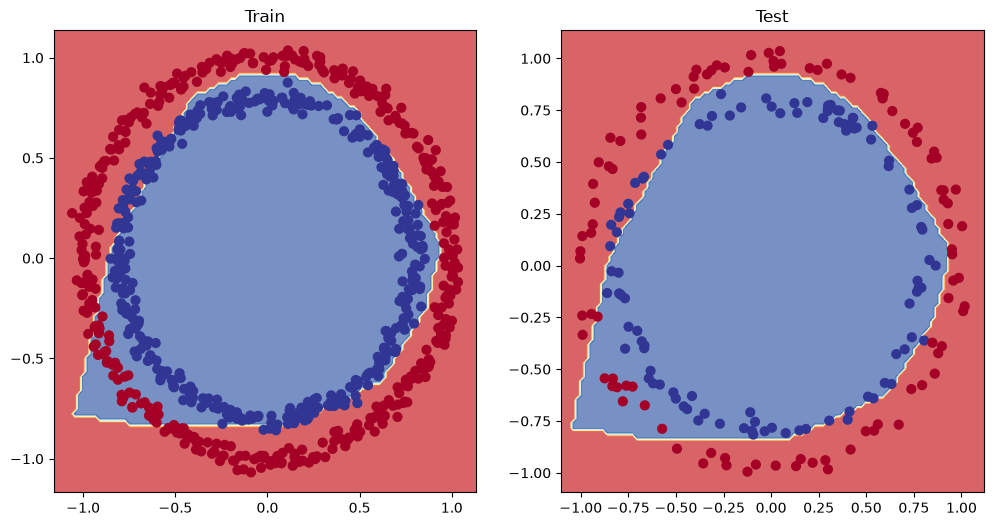

In [55]:
# Plot decision boundary of the model 
plt.figure(figsize=(12, 6))
plt.subplot(1,2,1)
plt.title("Train")
plot_decision_boundary(model_3, X_train, y_train)
plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(model_3, X_test, y_test)

# 7. Replicating non-linear activation functions

In [56]:
A = torch.arange(-10, 10, 1, dtype=torch.float32)
A

tensor([-10.,  -9.,  -8.,  -7.,  -6.,  -5.,  -4.,  -3.,  -2.,  -1.,   0.,   1.,
          2.,   3.,   4.,   5.,   6.,   7.,   8.,   9.])

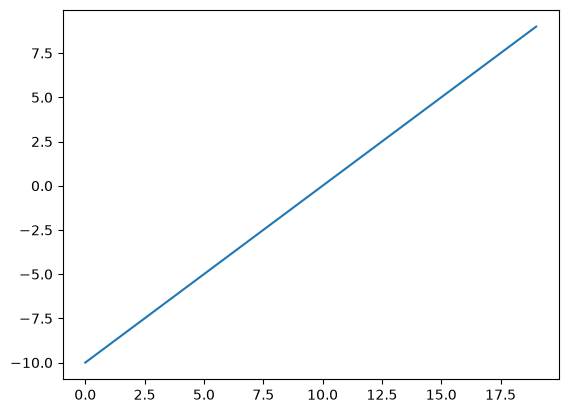

In [57]:
plt.plot(A)

In [58]:
torch.relu(A)

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 2., 3., 4., 5., 6., 7.,
        8., 9.])

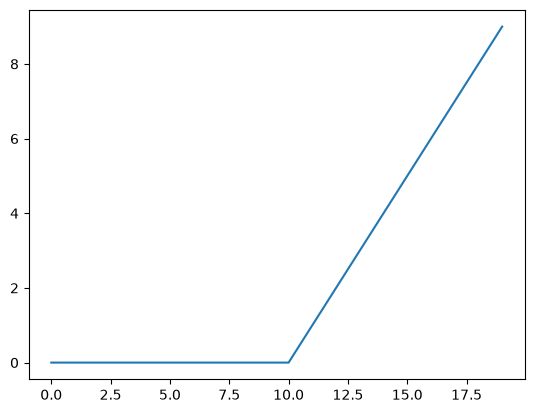

In [59]:
plt.plot(torch.relu(A))

In [60]:
def relu(x):
    return torch.maximum(torch.tensor(0), x)

relu(A)

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 2., 3., 4., 5., 6., 7.,
        8., 9.])

In [61]:
# now let's do sigmoid
def sigmoid(x):
    return 1/ (1 + torch.exp(-x))

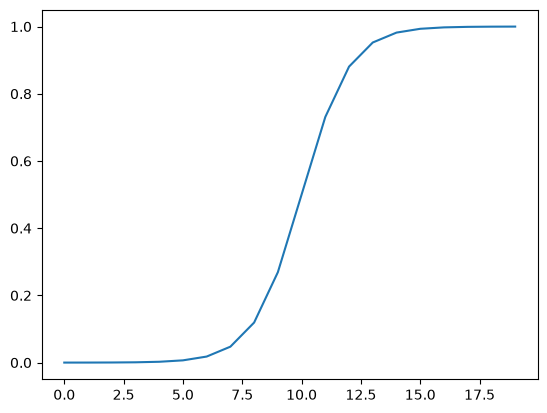

In [62]:
plt.plot(torch.sigmoid(A))

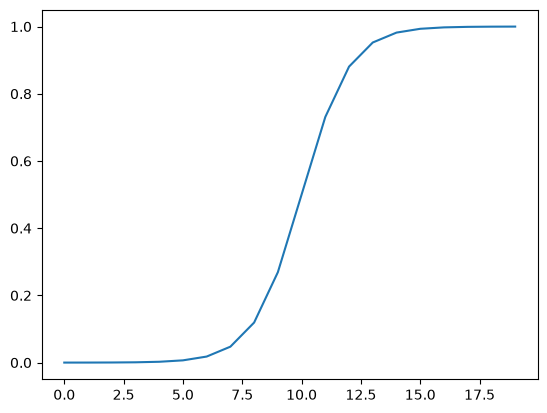

In [63]:
plt.plot(sigmoid(A))

# 8. Putting it all together with Multi Class Classification problem

In [64]:
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

# Hyper parameters
NUM_CLASSES = 4
NUM_FEATURES = 2
RANDOM_SEED = 42

X_blob, y_blob = make_blobs(n_samples=1000,
                           n_features=NUM_FEATURES,
                           centers=NUM_CLASSES,
                           cluster_std=2.5,
                           random_state=RANDOM_SEED)

# turn data into tensor 
X_blob = torch.from_numpy(X_blob).type(torch.float)
y_blob = torch.from_numpy(y_blob).type(torch.long)

X_blob_train, X_blob_test, y_blob_train, y_blob_test= train_test_split(X_blob, y_blob, test_size=0.2, random_state=RANDOM_SEED)

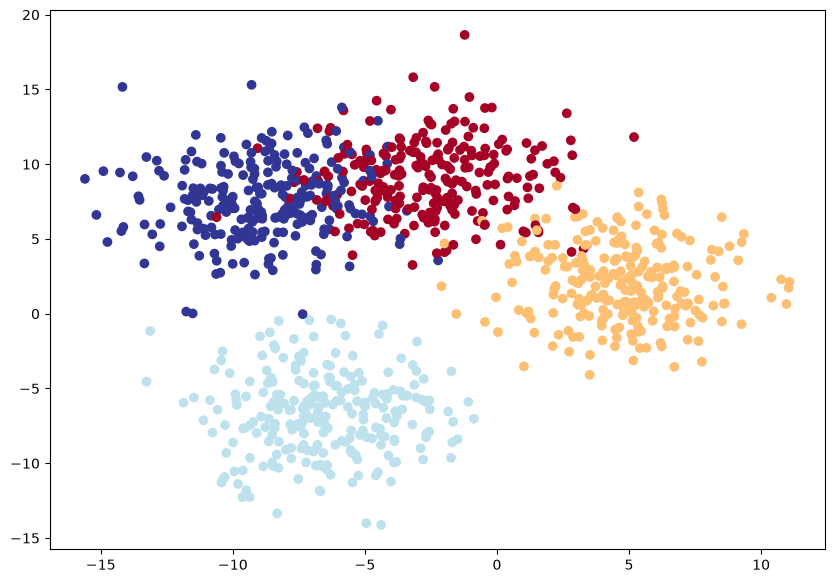

In [65]:
plt.figure(figsize=(10,7))
plt.scatter(X_blob[:, 0], X_blob[:, 1], c=y_blob, cmap=plt.cm.RdYlBu)

### 8.1 Building a multi classification model in Pytorch 

#### To do so, let's create a subclass of nn.Module that takes in three hyperparameters:

##### input_features - the number of X features coming into the model.
##### output_features - the ideal numbers of output features we'd like (this will be equivalent to NUM_CLASSES or the number of classes in your multi-class classification problem).
##### hidden_units - the number of hidden neurons we'd like each hidden layer to use

In [66]:
# Create device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [67]:
from torch import nn

# Build model
class BlobModel(nn.Module):
    def __init__(self, input_features, output_features, hidden_units=8):
        """
        Args:
            input_features (int): Number of input features to the model.
            out_features (int): Number of output features of the model
              (how many classes there are).
            hidden_units (int): Number of hidden units between layers, default 8.
        """
        super().__init__()
        self.linear_layer_stack = nn.Sequential(
            nn.Linear(in_features=input_features, out_features=hidden_units),
            nn.ReLU(), 
            nn.Linear(in_features=hidden_units, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=output_features), # how many classes are there?
        )
    
    def forward(self, x):
        return self.linear_layer_stack(x)

# Create an instance of BlobModel and send it to the target device
model_4 = BlobModel(input_features=NUM_FEATURES, 
                    output_features=NUM_CLASSES, 
                    hidden_units=8).to(device)
model_4

BlobModel(
  (linear_layer_stack): Sequential(
    (0): Linear(in_features=2, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=4, bias=True)
  )
)

### 8.2 Creating a loss function and optimizer for a multi-class PyTorch model

In [68]:
# Create loss and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_4.parameters(), 
                            lr=0.01)

### 8.3 Getting prediction probabilities for a multi-class PyTorch model

In [69]:
# Perform a single forward pass on the data (we'll need to put it to the target device for it to work)
model_4(X_blob_train.to(device))[:5]

tensor([[-0.8540, -0.7385, -1.6918, -1.2396],
        [-0.2570, -1.2709, -1.0271, -0.3026],
        [ 0.2528, -0.2379,  0.1882, -0.0066],
        [ 0.2191, -0.2774,  0.0959,  0.0405],
        [-0.0597, -0.8491, -0.5371, -0.1401]], device='cuda:0',
       grad_fn=<SliceBackward0>)

In [70]:
# How many elements in a single prediction sample
model_4(X_blob_train.to(device))[0].shape, NUM_CLASSES 

(torch.Size([4]), 4)

In [71]:
# Make prediction logits with model
y_logits = model_4(X_blob_test.to(device))

# Perform softmax calculation on logits across dimension 1 to get prediction probabilities
y_pred_probs = torch.softmax(y_logits, dim=1) 
print(y_logits[:5])
print(y_pred_probs[:5])

tensor([[-0.8454, -0.9351, -1.7552, -1.1825],
        [-0.0831, -0.9108, -0.5662, -0.1305],
        [ 0.2294, -0.2523,  0.1887,  0.0043],
        [-0.2811, -0.4618, -0.7089, -0.5499],
        [-0.3961, -1.5455, -1.4288, -0.4731]], device='cuda:0',
       grad_fn=<SliceBackward0>)
tensor([[0.3300, 0.3016, 0.1328, 0.2355],
        [0.3325, 0.1453, 0.2051, 0.3171],
        [0.2962, 0.1830, 0.2844, 0.2365],
        [0.3076, 0.2567, 0.2005, 0.2351],
        [0.3848, 0.1219, 0.1370, 0.3563]], device='cuda:0',
       grad_fn=<SliceBackward0>)


In [72]:
# Sum the first sample output of the softmax activation function 
torch.sum(y_pred_probs[0])

tensor(1., device='cuda:0', grad_fn=<SumBackward0>)

In [73]:
print(y_pred_probs[0])
print(torch.argmax(y_pred_probs[0]))

tensor([0.3300, 0.3016, 0.1328, 0.2355], device='cuda:0',
       grad_fn=<SelectBackward0>)
tensor(0, device='cuda:0')


### 8.4 Creating a training and testing loop for a multi-class PyTorch model

In [74]:
# Fit the model
torch.manual_seed(42)

# Set number of epochs
epochs = 400

# Put data to target device
X_blob_train, y_blob_train = X_blob_train.to(device), y_blob_train.to(device)
X_blob_test, y_blob_test = X_blob_test.to(device), y_blob_test.to(device)

for epoch in range(epochs):
    ### Training
    model_4.train()

    # 1. Forward pass
    y_logits = model_4(X_blob_train) # model outputs raw logits 
    y_pred = torch.softmax(y_logits, dim=1).argmax(dim=1) # go from logits -> prediction probabilities -> prediction labels
    # print(y_logits)
    # 2. Calculate loss and accuracy
    loss = loss_fn(y_logits, y_blob_train) 
    acc = accuracy_fn(y_true=y_blob_train,
                      y_pred=y_pred)

    # 3. Optimizer zero grad
    optimizer.zero_grad()

    # 4. Loss backwards
    loss.backward()

    # 5. Optimizer step
    optimizer.step()

    ### Testing
    model_4.eval()
    with torch.inference_mode():
      # 1. Forward pass
      test_logits = model_4(X_blob_test)
      test_pred = torch.softmax(test_logits, dim=1).argmax(dim=1)
      # 2. Calculate test loss and accuracy
      test_loss = loss_fn(test_logits, y_blob_test)
      test_acc = accuracy_fn(y_true=y_blob_test,
                             y_pred=test_pred)

    # Print out what's happening
    if epoch % 10 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Acc: {acc:.2f}% | Test Loss: {test_loss:.5f}, Test Acc: {test_acc:.2f}%") 

Epoch: 0 | Loss: 1.17675, Acc: 41.38% | Test Loss: 1.15886, Test Acc: 40.50%
Epoch: 10 | Loss: 1.09375, Acc: 54.37% | Test Loss: 1.09015, Test Acc: 53.50%
Epoch: 20 | Loss: 1.02317, Acc: 60.88% | Test Loss: 1.03004, Test Acc: 58.00%
Epoch: 30 | Loss: 0.96431, Acc: 67.00% | Test Loss: 0.97833, Test Acc: 65.00%
Epoch: 40 | Loss: 0.91500, Acc: 72.62% | Test Loss: 0.93366, Test Acc: 78.50%
Epoch: 50 | Loss: 0.87326, Acc: 82.75% | Test Loss: 0.89474, Test Acc: 84.00%
Epoch: 60 | Loss: 0.83734, Acc: 85.12% | Test Loss: 0.86043, Test Acc: 85.00%
Epoch: 70 | Loss: 0.80590, Acc: 86.00% | Test Loss: 0.82980, Test Acc: 86.50%
Epoch: 80 | Loss: 0.77786, Acc: 87.50% | Test Loss: 0.80207, Test Acc: 90.00%
Epoch: 90 | Loss: 0.75238, Acc: 87.75% | Test Loss: 0.77651, Test Acc: 89.50%
Epoch: 100 | Loss: 0.72879, Acc: 87.75% | Test Loss: 0.75248, Test Acc: 89.50%
Epoch: 110 | Loss: 0.70653, Acc: 88.50% | Test Loss: 0.72957, Test Acc: 90.00%
Epoch: 120 | Loss: 0.68534, Acc: 89.00% | Test Loss: 0.70757, T

### 8.5 Evaluating predictions with a PyTorch 

In [97]:
# Make predictions
model_4.eval()
with torch.inference_mode():
    y_logits = model_4(X_blob_test)

# View the first 10 predictions
y_logits[:10]

tensor([[ 0.0637,  3.4885, -6.5653, -6.1537],
        [-0.8873, -4.2664, -2.6664,  0.9561],
        [-1.4069, -1.7934,  1.2618, -1.1381],
        [-0.6696,  2.1927, -2.0388, -2.7472],
        [ 1.6460, -0.9234, -7.9566, -4.7150],
        [-1.5284, -5.5374, -3.3090,  1.6086],
        [-1.2057, -1.3028,  1.1948, -0.8165],
        [ 1.3482, -3.5168, -5.0438, -1.6353],
        [-2.0677, -2.7650,  1.4249, -1.7569],
        [ 1.6612, -2.5392, -5.7960, -2.5515]], device='cuda:0')

In [98]:
y_pred_probs = torch.softmax(y_logits, dim=1)

# Turn prediction probabilities into prediction labels
y_preds = y_pred_probs.argmax(dim=1)

# Compare first 10 model preds and test labels
print(f"Predictions: {y_preds[:10]}\nLabels: {y_blob_test[:10]}")
print(f"Test accuracy: {accuracy_fn(y_true=y_blob_test, y_pred=y_preds)}%")

Predictions: tensor([1, 3, 2, 1, 0, 3, 2, 0, 2, 0], device='cuda:0')
Labels: tensor([1, 3, 2, 1, 0, 3, 2, 0, 2, 0], device='cuda:0')
Test accuracy: 94.0%


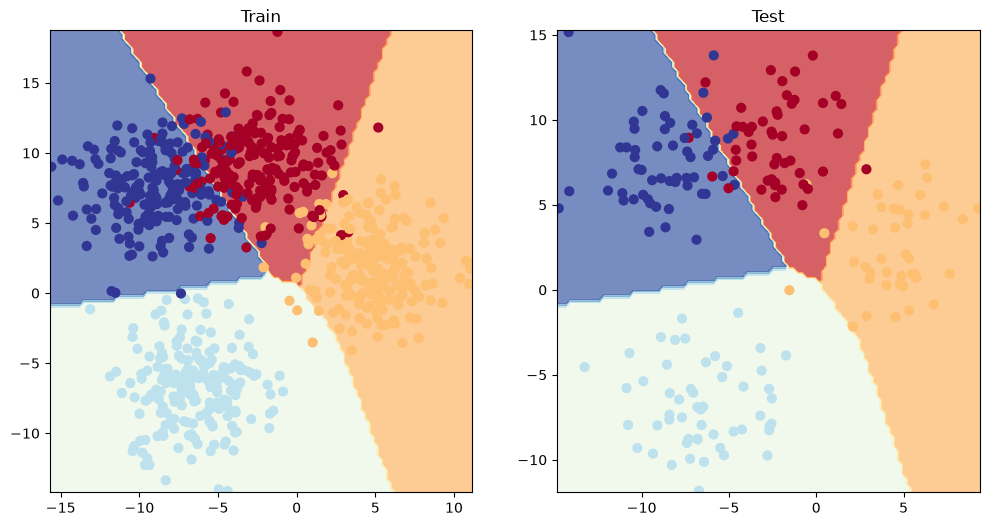

In [99]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_4, X_blob_train, y_blob_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_4, X_blob_test, y_blob_test)